# Diagnostics and Plotting

Before interpreting a fit, check that it converged. This example covers:

1. Reading `R_hat` and effective sample size from `summary()`.
2. Trace and posterior plots with `plot_trace` and `plot_dist`.
3. Posterior correctness plots with `plot_posterior_correctness`, for ungrouped and grouped models.

See the [Summaries and Diagnostics](../guide/summaries.rst) guide page for details.

In [1]:
import logging

import numpy as np
import pandas as pd
from cmdstanpy.utils import get_logger

# keep the notebook output readable, CmdStan progress is logged at INFO level
get_logger().setLevel(logging.WARNING)
import matplotlib.pyplot as plt

In [2]:
from stanbkt.fits import MCMCFitOptions
from stanbkt.models import StandardBKT
from stanbkt.utils import VerbosityLevel, sim_simple_BKT

data_df = sim_simple_BKT(n_students=60, n_problems=25, n_kcs=2, rng_seed=61,
                         learn=[0.08, 0.2], guess=0.2, slip=0.1)
fit_opts = MCMCFitOptions(seed=1234, iter_warmup=500, iter_sampling=500, show_progress=False)
model = StandardBKT(verbose=VerbosityLevel.WARN)
model.fit(data_df, stan_fit_options=fit_opts)

StandardBKT(fit_method=<FitMethod.MCMC: 'mcmc'>, verbose=<VerbosityLevel.WARN: 1>, is_fitted=True)

## Convergence diagnostics

For MCMC fits, check:

- `R_hat` below 1.01. Higher values mean the chains disagree.
- `ESS_bulk` and `ESS_tail` of at least 100 per chain (400 here, with 4 chains).

In [3]:
summary = model.summary()
diagnostics = summary[["R_hat", "ESS_bulk", "ESS_tail"]].drop(index="lp__", level="parameter")
flagged = diagnostics[(diagnostics["R_hat"] > 1.01) | (diagnostics["ESS_bulk"] < 400) | (diagnostics["ESS_tail"] < 400)]
print(f"{len(flagged)} of {len(diagnostics)} parameters flagged")
flagged

4 of 20 parameters flagged


R_hat  ESS_bulk  ESS_tail
kc_id parameter           axis     label                             
kc_0  logit_slip_group    group_id 1      1.01543   324.642   185.968
      slip                group_id 1      1.01543   324.642   185.968
kc_1  logit_pi_know_group group_id 1      1.00750   473.968   161.507
      pi_know             group_id 1      1.00750   473.968   161.507

Each parameter appears twice, on the logit scale (`logit_*_group`) and the probability scale, with the same diagnostics. Borderline values like these usually go away with more iterations, for example `MCMCFitOptions(iter_warmup=1000, iter_sampling=1000)`. Persistently high `R_hat` points to a weakly identified KC, see the uniform priors in the [Priors](04_priors.ipynb) example.

## Trace and posterior plots

`plot_trace` and `plot_dist` take the CmdStanPy fit of one KC, available from `model.fits.get_fit(kc)`. Well mixed chains look like overlapping, stationary noise.

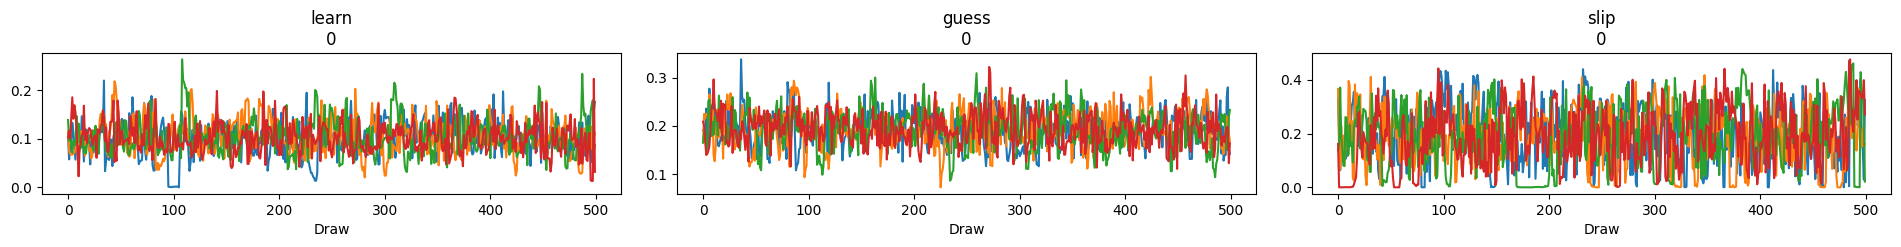

In [4]:
from stanbkt.plot import plot_dist, plot_trace

fit = model.fits.get_fit("kc_0")
plot_trace(fit, params=["learn", "guess", "slip"])
plt.show()

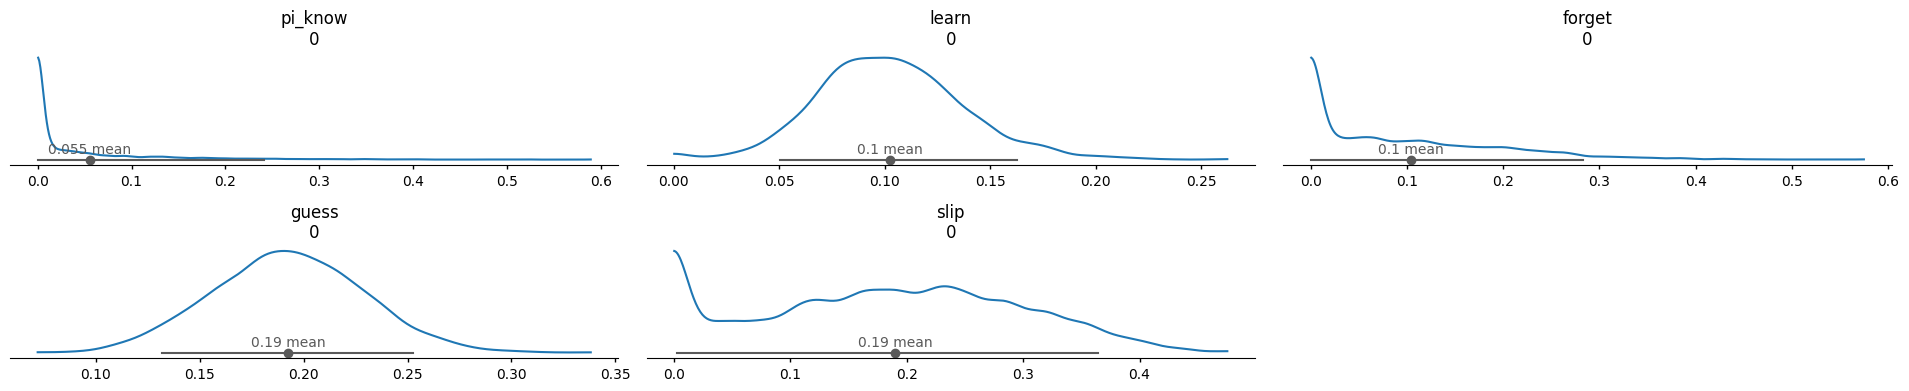

In [5]:
plot_dist(fit, params=["pi_know", "learn", "forget", "guess", "slip"], ci_prob=0.9)
plt.show()

## Posterior correctness

`plot_posterior_correctness` compares the observed proportion correct at each problem position with the model's posterior predictions. It takes the draw level output of one KC.

- `type="probs"` plots the posterior of `pCorrectness` with credible intervals.
- `type="preds"` plots correctness simulated from the posterior predictive distribution with predictive intervals.

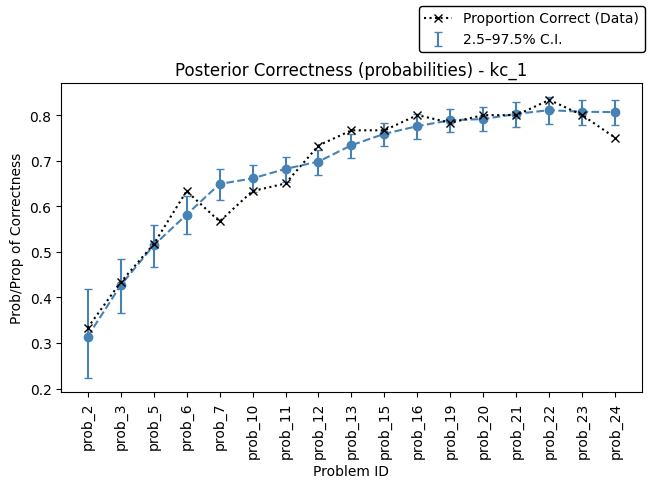

In [6]:
from stanbkt.plot import plot_posterior_correctness

draws = model.predict_posterior_draws(data_df, backend="numba")
plot_posterior_correctness(posterior_pred_kc=draws["kc_1"], data=data_df, kc="kc_1",
                           type="probs", trajectory=True, frac=1)
plt.show()

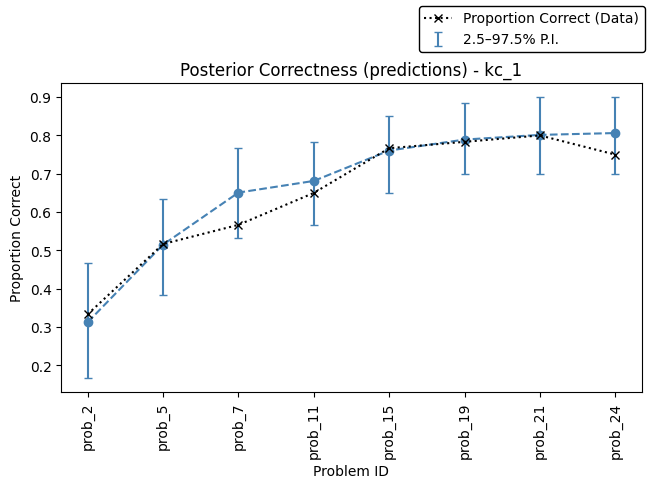

In [7]:
plot_posterior_correctness(posterior_pred_kc=draws["kc_1"], data=data_df, kc="kc_1",
                           type="preds", trajectory=True, frac=0.5)
plt.show()

## Grouped models

For `MultiBKT`, `grouped=True` draws one panel per group, so you can see where the groups' learning curves differ.

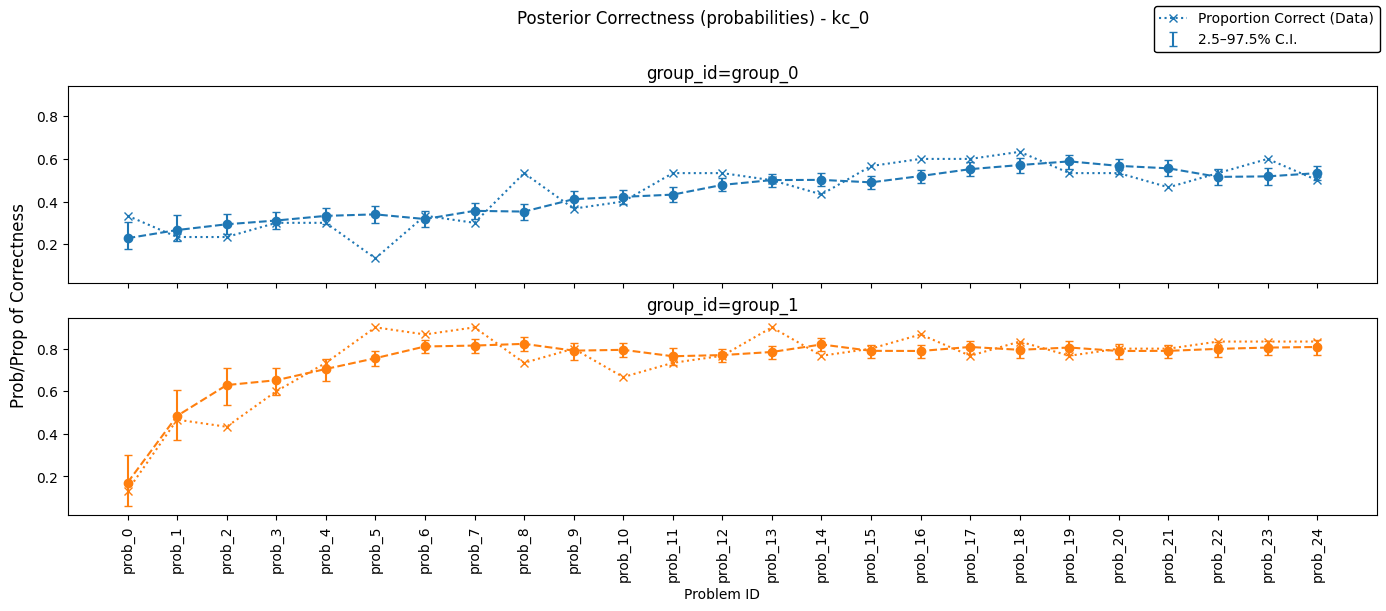

In [8]:
from stanbkt.models import MultiBKT
from stanbkt.utils import sim_grouped_BKT

grouped_df = sim_grouped_BKT(n_students=60, n_problems=25, n_kcs=1, n_groups=2, rng_seed=62,
                             learn=[0.05, 0.25], guess=0.2, slip=0.1)
multi = MultiBKT(verbose=VerbosityLevel.WARN)
multi.fit(grouped_df, stan_fit_options=fit_opts)

grouped_draws = multi.predict_posterior_draws(grouped_df, backend="numba")
plot_posterior_correctness(posterior_pred_kc=grouped_draws["kc_0"], data=grouped_df, kc="kc_0",
                           type="probs", trajectory=True, grouped=True, frac=1)
plt.show()